<a href="https://colab.research.google.com/github/h12d037-debug/ai/blob/main/%EA%B3%A0%EB%8F%85%EC%82%AC_%EC%98%88%EB%B0%A9%EC%9D%84_%EC%9C%84%ED%95%9C_AI_%EA%B8%B0%EB%B0%98_1%EB%8C%80_1_%EC%9D%BC%EC%83%81_%EA%B5%90%EB%A5%98_%EC%95%B1_%EC%84%A4%EA%B3%84.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

데이터 수집 및 가공, 시각화

1. 분석에 필요한 도구 준비하기




In [ ]:
# SAV 파일을 읽고, 그래프에 한글을 표시하는 도구를 설치한다.
%pip -q install pyreadstat koreanize-matplotlib

import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from google.colab import files

2. 원시자료와 코드북 불러오기

In [ ]:
# 업로드한 파일 중 확장자를 보고 원시자료와 코드북을 구분한다.
uploaded = files.upload()
sav_file = next(name for name in uploaded if name.lower().endswith(".sav"))
book_file = next(name for name in uploaded if name.lower().endswith(".xlsx"))

# 숫자 코드를 유지한 채 분석에 필요한 세 열만 읽는다.
data = pd.read_spss(sav_file, usecols=["DM1", "DM2", "Q2_1_1"], convert_categoricals=False)
print("전체 응답자 수:", len(data))
display(data.head())

Saving 2022 국민여가활동조사 원시자료.SAV to 2022 국민여가활동조사 원시자료.SAV
Saving 2022 국민여가활동조사 파일설계서(코드북).xlsx to 2022 국민여가활동조사 파일설계서(코드북).xlsx
전체 응답자 수: 10046


,Q2_1_1,DM1,DM2
0,25.0,2.0,6.0
1,74.0,2.0,3.0
2,58.0,2.0,3.0
3,77.0,2.0,7.0
4,72.0,1.0,7.0


3. 세 가지 핵심 속성 가공하기

In [ ]:
# 코드북의 B열과 C열에서 여가활동 코드와 활동 이름을 읽는다.
activity_codes = pd.read_excel(
    book_file,
    sheet_name="유형별 코드",
    usecols="B:C",
    header=None,
    nrows=93,
    names=["활동코드", "활동명"]
)

# 첫 행의 제목을 제외하고, 숫자 코드와 활동명이 있는 행만 남긴다.
activity_codes["활동코드"] = pd.to_numeric(activity_codes["활동코드"], errors="coerce")
activity_codes = activity_codes.dropna(subset=["활동코드", "활동명"])
activity_codes["활동명"] = activity_codes["활동명"].str.strip()
activity_names = activity_codes.set_index("활동코드")["활동명"].to_dict()

# 성별, 연령대, 여가활동 1순위를 각각 알아보기 쉬운 값으로 바꾼다.
data["성별"] = data["DM1"].map({1: "남성", 2: "여성"})
data["연령대"] = data["DM2"].map({
    1: "15~19세", 2: "20대", 3: "30대", 4: "40대",
    5: "50대", 6: "60대", 7: "70대 이상"
})
data["여가활동 1순위"] = data["Q2_1_1"].map(activity_names)

# 원래 코드와 가공한 값이 나란히 나타나는지 확인한다.
display(data[["DM1", "성별", "DM2", "연령대", "Q2_1_1", "여가활동 1순위"]].head())

,DM1,성별,DM2,연령대,Q2_1_1,여가활동 1순위
0,2.0,여성,6.0,60대,25.0,수영
1,2.0,여성,3.0,30대,74.0,TV시청(IPTV 포함)
2,2.0,여성,3.0,30대,58.0,인터넷 검색/1인 미디어 제작/SNS/영상편집
3,2.0,여성,7.0,70대 이상,77.0,음악 감상
4,1.0,남성,7.0,70대 이상,72.0,목욕/사우나/찜질방


4. 50대 남성의 응답을 골라 상위 5개 활동 구하기

In [ ]:
# 김철수 씨와 같은 50대 남성 응답자만 선택한다.
target = data[(data["성별"] == "남성") & (data["연령대"] == "50대")]

# 한 사람이 선택한 1순위 활동 하나씩을 세고, 상위 5개를 구한다.
counts = target["여가활동 1순위"].value_counts()
top5 = counts.head(5)

print("50대 남성 응답자 수:", len(target))
print("활동명이 확인된 응답 수:", counts.sum())
display(top5.to_frame(name="응답자 수(명)"))

50대 남성 응답자 수: 887
활동명이 확인된 응답 수: 887


,응답자 수(명)
여가활동 1순위,
TV시청(IPTV 포함),425
산책 및 걷기,55
"모바일 컨텐츠, 동영상, VOD 시청, OTT 시청",50
"스포츠 경기 간접관람- TV, DMB를 통한관람(축구, 야구, 농구, 배구 등)",35
인터넷 검색/1인 미디어 제작/SNS/영상편집,31


5. 가로 막대그래프 그리기

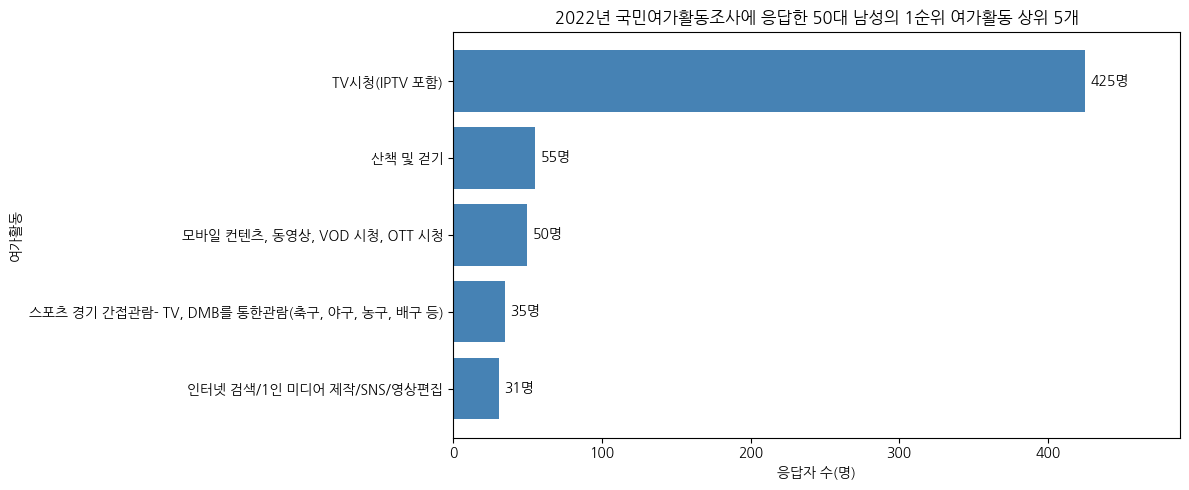

In [ ]:
# 활동 이름이 길어서 가로 막대그래프를 사용한다.
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(top5.index, top5.values, color="steelblue")

# 가장 많이 나온 활동을 맨 위에 표시하고 막대 끝에 인원수를 적는다.
ax.invert_yaxis()
ax.bar_label(bars, fmt="%d명", padding=4)
ax.set_xlim(0, top5.max() * 1.15)
ax.set_title("2022년 국민여가활동조사에 응답한 50대 남성의 1순위 여가활동 상위 5개")
ax.set_xlabel("응답자 수(명)")
ax.set_ylabel("여가활동")

plt.tight_layout()
plt.show()

 AI 기반 1대 1 일상 교류 앱 설계

1. 선택지와 시연용 대화 상대 준비하기

In [ ]:
# 사용자가 선택할 대화 방식, 요일, 시간, 연락 빈도를 준비한다.
import ipywidgets as widgets
from IPython.display import display, clear_output

대화방식 = ["음성 통화", "영상 통화", "문자"]
요일목록 = ["월요일", "화요일", "수요일", "목요일", "금요일", "토요일", "일요일"]
빈도목록 = ["주 1회", "주 2회", "주 4회", "매일"]

# 하루를 00~02시부터 22~24시까지 2시간 단위로 나눈다.
시간목록 = [f"{시:02d}~{시 + 2:02d}시" for 시 in range(0, 24, 2)]

# 앞에서 분석한 여가활동을 참고해 대화 주제 선택지를 정한다.
주제목록 = ["TV·방송", "산책·동네 이야기", "영화·OTT", "스포츠", "인터넷·영상", "일상"]

# 아래 세 명은 추천 기능을 시험하기 위한 가상 사용자다.
후보목록 = [
    {
        "별명": "느티나무",
        "방식": ["음성 통화", "문자"],
        "가능시간": [("수요일", "18~20시"), ("토요일", "10~12시")],
        "빈도": "주 1회",
        "주제": ["TV·방송", "스포츠"]
    },
    {
        "별명": "별하늘",
        "방식": ["음성 통화", "영상 통화"],
        "가능시간": [("금요일", "10~12시"), ("수요일", "18~20시")],
        "빈도": "주 2회",
        "주제": ["영화·OTT", "TV·방송"]
    },
    {
        "별명": "바다",
        "방식": ["영상 통화", "문자"],
        "가능시간": [("일요일", "14~16시")],
        "빈도": "매일",
        "주제": ["인터넷·영상", "산책·동네 이야기", "일상"]
    }
]

print("대화 방식 3개, 하루 시간 구간 12개, 연락 빈도 4개를 준비했습니다.")

대화 방식 3개, 하루 시간 구간 12개, 연락 빈도 4개를 준비했습니다.


2. 규칙 기반 추론과 탐색으로 상대 추천하기

In [ ]:
def 상대_추천(내방식, 내시간, 내빈도, 내주제):
    추천결과 = []

    for 후보 in 후보목록:
        # 두 사람이 공통으로 선택한 방식, 시간, 주제를 찾는다.
        공통방식 = [방식 for 방식 in 내방식 if 방식 in 후보["방식"]]
        공통시간 = [시간 for 시간 in 내시간 if 시간 in 후보["가능시간"]]
        공통주제 = [주제 for 주제 in 내주제 if 주제 in 후보["주제"]]

        # 규칙 기반 추론: 네 조건의 일치 여부를 각각 판단한다.
        조건 = {
            "대화 방식": len(공통방식) > 0,
            "가능 시간": len(공통시간) > 0,
            "연락 빈도": 내빈도 == 후보["빈도"],
            "대화 주제": len(공통주제) > 0
        }

        # True는 1점, False는 0점으로 합산한다.
        점수 = sum(조건.values())

        if 점수 >= 3:
            추천결과.append({
                "후보": 후보,
                "점수": 점수,
                "조건": 조건,
                "공통방식": 공통방식,
                "공통시간": 공통시간,
                "공통주제": 공통주제
            })

    # 탐색: 모든 후보를 확인한 뒤 4점 후보를 3점 후보보다 먼저 보여 준다.
    추천결과.sort(key=lambda 결과: 결과["점수"], reverse=True)
    return 추천결과

3. 사용자가 조건을 선택하는 화면 만들기

In [ ]:
# 여러 개를 선택할 수 있는 항목은 체크박스로 만든다.
방식체크 = [widgets.Checkbox(value=(x == "음성 통화"), description=x) for x in 대화방식]
주제체크 = [widgets.Checkbox(value=(x == "TV·방송"), description=x) for x in 주제목록]

요일선택 = widgets.Dropdown(options=요일목록, value="수요일", description="요일")
시간선택 = widgets.Dropdown(options=시간목록, value="18~20시", description="시간")
빈도선택 = widgets.Dropdown(options=빈도목록, description="연락 빈도")

추가버튼 = widgets.Button(description="시간 추가")
삭제버튼 = widgets.Button(description="선택한 시간 삭제")
추천버튼 = widgets.Button(description="대화 상대 추천받기", button_style="success")
결과창 = widgets.Output()

# 등록한 시간은 목록에 표시한다. 목록에서 하나를 골라 삭제할 수도 있다.
등록시간 = widgets.Select(options=[], rows=3, description="등록 시간")

def 시간_추가(버튼):
    새시간 = (요일선택.value, 시간선택.value)
    기존목록 = list(등록시간.options)
    # 각 항목에는 화면에 보이는 글자와 실제 (요일, 시간) 값이 들어간다.
    if 새시간 not in [값 for 글자, 값 in 기존목록]:
        기존목록.append((f"{새시간[0]} {새시간[1]}", 새시간))
        등록시간.options = 기존목록

def 시간_삭제(버튼):
    선택값 = 등록시간.value
    등록시간.options = [(글자, 값) for 글자, 값 in 등록시간.options if 값 != 선택값]

def 결과_표시(버튼):
    with 결과창:
        clear_output(wait=True)
        내방식 = [칸.description for 칸 in 방식체크 if 칸.value]
        내주제 = [칸.description for 칸 in 주제체크 if 칸.value]
        내시간 = [값 for 글자, 값 in 등록시간.options]

        if not 내방식 or not 내주제:
            print("대화 방식과 대화 주제를 각각 한 가지 이상 선택해 주세요.")
            return

        if "문자" not in 내방식 and not 내시간:
            print("통화를 원하면 요일과 시간을 고른 뒤 ‘시간 추가’를 눌러 주세요.")
            return

        결과목록 = 상대_추천(내방식, 내시간, 빈도선택.value, 내주제)
        if not 결과목록:
            print("현재 네 가지 조건 중 3개 이상 일치하는 상대가 없습니다.")
            return

        for 결과 in 결과목록:
            후보 = 결과["후보"]
            일치항목 = [이름 for 이름, 일치 in 결과["조건"].items() if 일치]

            print(f'추천 상대: {후보["별명"]} ({결과["점수"]}/4개 일치)')
            print("일치한 조건:", ", ".join(일치항목))
            print("공통 대화 방식:", ", ".join(결과["공통방식"]) or "없음")
            print("상대의 희망 연락 빈도:", 후보["빈도"])
            print("공통 대화 주제:", ", ".join(결과["공통주제"]) or "없음")

            if 결과["공통시간"]:
                시간표시 = [f"{요일} {시간}" for 요일, 시간 in 결과["공통시간"]]
                print("겹치는 시간:", ", ".join(시간표시))
            elif not 내시간:
                print("겹치는 시간: 내 통화 시간 미등록")
            else:
                print("겹치는 시간: 없음")

            # 3점 후보에게 실제로 어떤 조율이 필요한지 안내한다.
            if not 결과["조건"]["대화 방식"]:
                print("조율할 점: 두 사람이 사용할 대화 방식을 먼저 정해야 해요.")
            elif not 결과["조건"]["가능 시간"]:
                if "문자" in 결과["공통방식"]:
                    print("문자는 각자 편한 시간에 주고받을 수 있어요.")
                else:
                    print("조율할 점: 통화하려면 새로운 시간을 정해야 해요.")
            elif not 결과["조건"]["연락 빈도"]:
                print("조율할 점: 서로 편한 연락 횟수를 정해 보세요.")
            elif not 결과["조건"]["대화 주제"]:
                print("조율할 점: 첫 대화에서 함께 이야기할 주제를 정해 보세요.")
            print()

추가버튼.on_click(시간_추가)
삭제버튼.on_click(시간_삭제)
추천버튼.on_click(결과_표시)

display(
    widgets.HTML("<h2>안부 한마디 · 대화 상대 추천</h2>"),
    widgets.HTML("<b>1. 원하는 대화 방식</b> (여러 개 선택 가능)"),
    widgets.VBox(방식체크),
    widgets.HTML("<b>2. 이번 주 통화 가능 시간</b><br>요일과 시간을 골라 추가하세요. 문자만 원하면 비워 두어도 됩니다."),
    요일선택, 시간선택, 추가버튼, 등록시간, 삭제버튼,
    widgets.HTML("<b>3. 희망 연락 빈도</b>"),
    빈도선택,
    widgets.HTML("<b>4. 이야기하고 싶은 주제</b> (여러 개 선택 가능)"),
    widgets.VBox(주제체크),
    추천버튼, 결과창)

HTML(value='<h2>안부 한마디 · 대화 상대 추천</h2>')

HTML(value='<b>1. 원하는 대화 방식</b> (여러 개 선택 가능)')

HTML(value='<b>2. 이번 주 통화 가능 시간</b><br>요일과 시간을 골라 추가하세요. 문자만 원하면 비워 두어도 됩니다.')

Dropdown(description='요일', index=2, options=('월요일', '화요일', '수요일', '목요일', '금요일', '토요일', '일요일'), value='수요일')

Dropdown(description='시간', index=9, options=('00~02시', '02~04시', '04~06시', '06~08시', '08~10시', '10~12시', '12~1…

Button(description='시간 추가', style=ButtonStyle())

... (3 outputs left out)

Dropdown(description='연락 빈도', options=('주 1회', '주 2회', '주 4회', '매일'), value='주 1회')

HTML(value='<b>4. 이야기하고 싶은 주제</b> (여러 개 선택 가능)')

Button(button_style='success', description='대화 상대 추천받기', style=ButtonStyle())

Output()